In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

In [ ]:
# Load data
df = yf.download('SPY', start="2000-01-01", end="2020-01-01")
df.head()

/tmp/ipykernel_1601/873884209.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download('SPY', start="2000-01-01", end="2020-01-01")
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,SPY,SPY,SPY,SPY,SPY
Date,,,,,
2000-01-03,91.367523,93.134407,90.385921,93.134407,8164300
2000-01-04,87.794510,90.503732,87.725798,90.169987,8089800
2000-01-05,87.951553,88.913523,86.223934,87.912289,12177900
2000-01-06,86.538055,88.893901,86.538055,87.715978,6227200
2000-01-07,91.563873,91.563873,87.990840,88.147897,8066500


In [ ]:
if isinstance(df.columns, pd.MultiIndex):
  df.columns = df.columns.get_level_values(0)

In [ ]:
# Features
df["ret_5"] = df["Close"].pct_change(5)
df["ret_20"] = df["Close"].pct_change(20)

In [ ]:
# Target
df["future_return"] = df["Close"].pct_change().shift(-1)
df["target"] = (df["future_return"] > 0).astype(int)

In [ ]:
# Preparing the data

data = df[["ret_5", "ret_20", "target", "future_return"]].dropna()
X = data[["ret_5", "ret_20"]]
y = data["target"]

In [ ]:
# Initialize the model
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

In [ ]:
# Fit/train the model
model.fit(X, y)

LogisticRegression()

In [ ]:
# Generate predictions
probs = model.predict_proba(X)
data["prob_up"] = probs[:, 1]

In [ ]:
# Evaluate training accuracy
data["pred"] = (data["prob_up"] > 0.5).astype(int)
accuracy = (data["pred"] == y).mean()
print("Accuracy:", accuracy)

Accuracy: 0.5439121756487026


In [ ]:
# Trade signal
data["position"] = np.where(data["prob_up"] > 0.5, 1, -1)

In [ ]:
# Simulate strategy returns
data["strategy_return"] = data["position"] * data["future_return"]
data["equity_curve"] = (1 + data["strategy_return"]).cumprod()
data["buy_and_hold"] = (1 + data["future_return"]).cumprod()

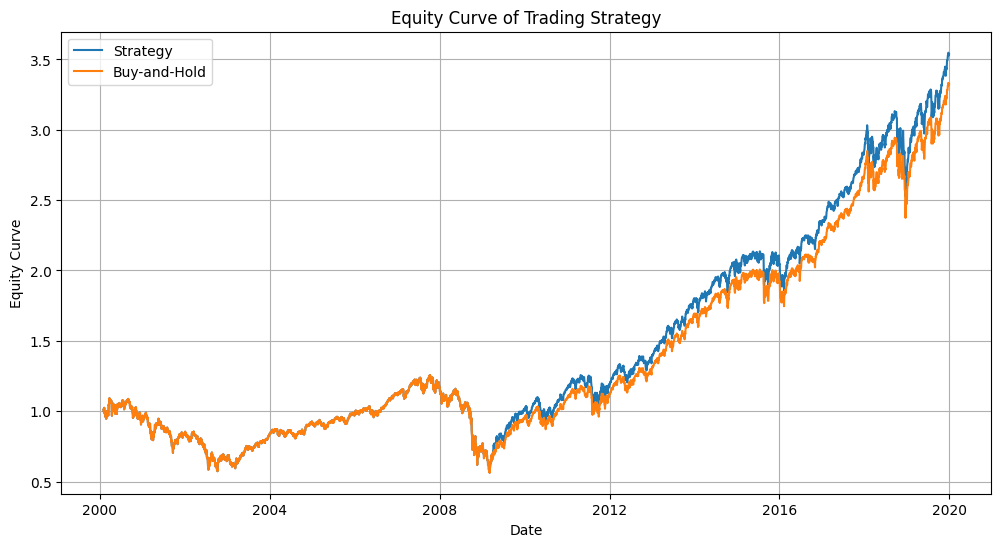

In [ ]:
# Plot equity curve vs. buy-and-hold
plt.figure(figsize=(12, 6))
plt.plot(data["equity_curve"])
plt.plot(data["buy_and_hold"])
plt.legend(["Strategy", "Buy-and-Hold"])
plt.xlabel("Date")
plt.ylabel("Equity Curve")
plt.title("Equity Curve of Trading Strategy")
plt.grid(True)
plt.show()

In [ ]:
# Evaluate
sharpe = np.sqrt(252) * data["strategy_return"].mean() / data["strategy_return"].std()
sharpe_buy_and_hold = np.sqrt(252) * data["future_return"].mean() / data["future_return"].std()
print("Strategy Sharpe:", sharpe)
print("Buy-and-hold Sharpe:", sharpe_buy_and_hold)

Strategy Sharpe: 0.4307411463410064
Buy-and-hold Sharpe: 0.4141339357593301


## With Train-Test Split

In [ ]:
# Define the walk-forward window
train_size = 1000
test_size = 250

In [ ]:
# Result storage
sharpe_ratios = []
benchmark_sharpe_ratios = []

In [ ]:
for start in range(0, len(data) - train_size - test_size, test_size):
  # Select train/test sets
  X_train = data[["ret_5", "ret_20"]].iloc[start:start + train_size]
  y_train = data["target"].iloc[start:start + train_size]
  X_test = data[["ret_5", "ret_20"]].iloc[start + train_size:start + train_size + test_size]
  y_test = data["target"].iloc[start + train_size:start + train_size + test_size]

  # Train model
  model = LogisticRegression()
  model.fit(X_train, y_train)

  # Generate predictions
  probs = model.predict_proba(X_test)
  pred_probs = probs[:, 1]

  # Convert predictions into trading signal
  positions = np.where(pred_probs > 0.5, 1, -1)

  # Compute strategy returns
  market_returns = data["future_return"].iloc[start + train_size:start + train_size + test_size]
  strategy_returns = positions * market_returns
  sharpe = np.sqrt(252) * strategy_returns.mean() / strategy_returns.std()
  sharpe_ratios.append(sharpe)
  benchmark_sharpe = np.sqrt(252) * market_returns.mean() / market_returns.std()
  benchmark_sharpe_ratios.append(benchmark_sharpe)

In [ ]:
# Compute walk-foward statistics
mean_sharpe = np.mean(sharpe_ratios)
std_sharpe = np.std(sharpe_ratios)
mean_sharpe, std_sharpe

(np.float64(0.9516793620101371), np.float64(0.9291531840674596))

In [ ]:
# Is the strategy statistically better than buy-and-hold?
from scipy.stats import ttest_ind
t_stat, p_val = ttest_ind(sharpe_ratios, benchmark_sharpe_ratios, alternative='greater')
print("t-statistic:", t_stat)
print("p-value:", p_val)

t-statistic: 0.06645342740497423
p-value: 0.4737288662930294
